####Import Required Libraries

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import date, timedelta

# Display settings
np.set_printoptions(suppress=True, precision=2)

print("Libraries imported successfully.")

Libraries imported successfully.


####Cleaning the dataset

In [41]:
def load_data(path):

    data = np.load(path, allow_pickle=False)

    required = ["net_cash", "agent_ids", "start_date", "interval_minutes"]

    assert all(key in data.files for key in required)

    print("Dataset loaded successfully.")
    print("Available arrays:", data.files)

    for key in required:
        print(key, ":", data[key].shape)

    return data


data = load_data("group01_pos.npz")

Dataset loaded successfully.
Available arrays: ['net_cash', 'agent_ids', 'start_date', 'interval_minutes']
net_cash : (967680,)
agent_ids : (120,)
start_date : ()
interval_minutes : ()


####Reshaping the data

In [29]:
def reshape_data(data):

    flat = data["net_cash"].astype(np.float64)

    n_agents = len(data["agent_ids"])
    intervals_per_day = 24 * 12

    assert data["interval_minutes"].item() == 5

    assert flat.size % (n_agents * intervals_per_day) == 0

    n_days = flat.size // (n_agents * intervals_per_day)

    cash = flat.reshape(
        n_agents,
        n_days,
        24,
        12
    )

    assert cash.shape == (120, 28, 24, 12)

    print("Number of agents:", n_agents)
    print("Number of days:", n_days)
    print("Reshaped data:", cash.shape)

    return cash


cash = reshape_data(data)

Number of agents: 120
Number of days: 28
Reshaped data: (120, 28, 24, 12)


####Problem 1: one whole day recorded in kobo (100 times too big)

In [30]:
def detect_scale_error(cash):

    daily_activity = np.median(
        np.sum(np.abs(cash), axis=(2, 3)),
        axis=0
    )

    normal_activity = np.median(daily_activity)

    ratios = daily_activity / normal_activity

    affected_days = np.where(
        (ratios >= 85) & (ratios <= 115)
    )[0]

    assert len(affected_days) == 1, ("Could not uniquely identify the scale error.")

    day_idx = affected_days[0]

    print("Scale error detected.")
    print("Affected day index:", day_idx)
    print("Scale ratio:", ratios[day_idx])

    return day_idx


scale_day = detect_scale_error(cash)

Scale error detected.
Affected day index: 10
Scale ratio: 101.01974325415611


####Problem 2: one agent's day uploaded twice (exact copy of the day before)

In [31]:
def detect_duplicate_day(cash, agent_ids):

    matches = []

    for agent in range(cash.shape[0]):

        equal_days = np.all(
            cash[agent, 1:] == cash[agent, :-1],
            axis=(1, 2)
        )

        days = np.where(equal_days)[0] + 1

        for day_idx in days:
            matches.append((agent, day_idx))

    assert len(matches) == 1, (
        "Expected exactly one duplicated day."
    )

    agent_idx, day_idx = matches[0]

    print("Duplicate detected.")
    print("Agent:", agent_ids[agent_idx])
    print("Duplicated day index:", day_idx)

    return agent_idx, day_idx


duplicate_agent, duplicate_day = detect_duplicate_day(
    cash,
    data["agent_ids"]
)

Duplicate detected.
Agent: AG1028
Duplicated day index: 7


####Problem 3: one agent's clock is one hour late

In [32]:
def detect_clock_shift(cash):

    # Remove the known scale error before comparison.
    corrected = cash.copy()
    corrected[:, scale_day] /= 100

    # Average absolute activity by time of day.
    profiles = np.mean(
        np.abs(corrected),
        axis=1
    ).reshape(cash.shape[0], 288)

    # Create a reference profile for each agent
    # using all other agents.
    references = np.stack([
        np.median(
            np.delete(profiles, agent, axis=0),
            axis=0
        )
        for agent in range(cash.shape[0])
    ])

    def correlation(x, y):
        x_centered = x - np.mean(x, axis=1, keepdims=True)
        y_centered = y - np.mean(y, axis=1, keepdims=True)

        numerator = np.sum(
            x_centered * y_centered,
            axis=1
        )

        denominator = np.sqrt(
            np.sum(x_centered ** 2, axis=1) *
            np.sum(y_centered ** 2, axis=1)
        )

        return numerator / np.maximum(denominator, 1e-12)

    correlations = []

    shifts = range(-2, 3)

    for shift in shifts:

        shifted = np.roll(
            profiles,
            shift * 12,
            axis=1
        )

        correlations.append(
            correlation(shifted, references)
        )

    correlations = np.stack(correlations, axis=1)

    best_positions = np.argmax(correlations, axis=1)

    best_correlations = np.max(correlations, axis=1)

    original_correlations = correlations[:, 2]

    improvements = best_correlations - original_correlations

    candidates = np.where(
        (best_positions != 2) &
        (improvements > 0.03)
    )[0]

    assert len(candidates) == 1, (
        "Could not uniquely identify the clock-shifted agent."
    )

    agent_idx = candidates[np.argmax(improvements[candidates])]

    shift_hours = list(shifts)[best_positions[agent_idx]]

    print("Clock shift detected.")
    print("Agent index:", agent_idx)
    print("Alignment shift:", shift_hours, "hour(s)")

    return agent_idx, shift_hours


clock_agent, clock_shift = detect_clock_shift(cash)

Clock shift detected.
Agent index: 58
Alignment shift: -1 hour(s)


####Correcting the Data


In [33]:
def clean_data(
    cash,
    scale_day,
    duplicate_agent,
    duplicate_day,
    clock_agent,
    clock_shift
):

    cleaned = cash.copy()

    # 1. Correct the kobo error.
    cleaned[:, scale_day, :, :] /= 100

    # 2. Correct the one-hour timestamp shift.
    intervals_to_shift = clock_shift * 12

    cleaned[clock_agent] = np.roll(
        cleaned[clock_agent],
        intervals_to_shift,
        axis=2
    )

    assert cleaned.shape == cash.shape

    print("Data cleaning completed.")

    return cleaned


cash_clean = clean_data(
    cash,
    scale_day,
    duplicate_agent,
    duplicate_day,
    clock_agent,
    clock_shift
)

Data cleaning completed.


####Analysing the cleaned data

In [34]:
def member3_analysis(cash_clean):
    n_agents, n_days = cash_clean.shape[:2]

    # Reshape five-minute readings into 288 daily intervals.
    cash_5min = cash_clean.reshape(
        n_agents,
        n_days,
        288
    )

    assert cash_5min.shape == (n_agents, n_days, 288)

    # Calculate running cash movement during each day.
    cumulative_cash = np.cumsum(
        cash_5min,
        axis=2
    )

    assert cumulative_cash.shape == (n_agents, n_days, 288)

    # Aggregate twelve five-minute readings into one hour.
    hourly_cash = cash_5min.reshape(
        n_agents,
        n_days,
        24,
        12
    ).sum(axis=3)

    assert hourly_cash.shape == (n_agents, n_days, 24)

    # Calculate total net cash movement for each day.
    daily_net_cash = np.sum(
        cash_5min,
        axis=2
    )

    assert daily_net_cash.shape == (n_agents, n_days)

    print("\nMEMBER 3: NUMPY ANALYSIS")
    print("Five-minute data:", cash_5min.shape)
    print("Cumulative cash:", cumulative_cash.shape)
    print("Hourly cash:", hourly_cash.shape)
    print("Daily net cash:", daily_net_cash.shape)

    return {
        "cash_5min": cash_5min,
        "cumulative_cash": cumulative_cash,
        "hourly_cash": hourly_cash,
        "daily_net_cash": daily_net_cash
    }


In [35]:
member3_results = member3_analysis(cash_clean)


MEMBER 3: NUMPY ANALYSIS
Five-minute data: (120, 28, 288)
Cumulative cash: (120, 28, 288)
Hourly cash: (120, 28, 24)
Daily net cash: (120, 28)


####Calculate the opening cash requirements

In [36]:
def calculate_opening_float(
    cash_clean,
    duplicate_agent,
    duplicate_day
):

    n_agents, n_days = cash_clean.shape[:2]

    # Reshape to (agents, days, 288).
    daily_cash = cash_clean.reshape(
        n_agents,
        n_days,
        288
    )

    assert daily_cash.shape == (120, 28, 288)

    # Calculate cumulative cash movement.
    running_cash = np.cumsum(
        daily_cash,
        axis=2
    )

    # Highest cumulative cash requirement per day.
    daily_need = np.maximum(
        np.max(running_cash, axis=2),
        0
    )

    assert daily_need.shape == (120, 28)

    # Exclude the duplicated observation.
    daily_need[
        duplicate_agent,
        duplicate_day
    ] = np.nan

    # Calculate the 95th percentile per agent.
    recommended_float = np.nanpercentile(
        daily_need,
        95,
        axis=1
    )

    typical_float = np.median(recommended_float)

    total_float = np.sum(recommended_float)

    print("Median opening float: ₦{:,.2f}".format(
        typical_float
    ))

    print("Total recommended opening cash: ₦{:,.2f}".format(
        total_float
    ))

    return daily_need, recommended_float


daily_need, agent_float = calculate_opening_float(
    cash_clean,
    duplicate_agent,
    duplicate_day
)

Median opening float: ₦1,145,455.00
Total recommended opening cash: ₦153,412,122.50


####Ranking the agents by opening cash requirement

In [37]:
def rank_agents(agent_float, agent_ids):

    ranking = np.argsort(agent_float)[::-1]

    print("\nTOP 10 AGENTS BY OPENING CASH REQUIREMENT")

    for position, idx in enumerate(ranking[:10], start=1):

        print(
            position,
            agent_ids[idx],
            "₦{:,.2f}".format(agent_float[idx])
        )

    return ranking


ranking = rank_agents(
    agent_float,
    data["agent_ids"]
)


TOP 10 AGENTS BY OPENING CASH REQUIREMENT
1 AG1021 ₦5,072,567.50
2 AG1097 ₦3,847,390.00
3 AG1041 ₦2,957,525.00
4 AG1036 ₦2,822,105.00
5 AG1077 ₦2,336,785.00
6 AG1000 ₦2,150,137.50
7 AG1100 ₦2,058,452.50
8 AG1115 ₦2,050,435.00
9 AG1031 ₦2,046,030.00
10 AG1091 ₦2,032,155.00


####Identify the largest night-time payout

In [38]:
def detect_night_alert(cash_clean, agent_ids, start_date):

    # Aggregate five-minute readings into hourly values.
    hourly_cash = np.sum(
        cash_clean,
        axis=3
    )

    assert hourly_cash.shape == (120, 28, 24)

    # Midnight to 05:00.
    night_cash = hourly_cash[:, :, 0:5]

    # Find the largest positive net cash outflow.
    positive_cash = np.maximum(night_cash, 0)

    flat_index = np.argmax(positive_cash)

    agent_idx, day_idx, hour_idx = np.unravel_index(
        flat_index,
        positive_cash.shape
    )

    amount = positive_cash[
        agent_idx,
        day_idx,
        hour_idx
    ]

    alert_date = date.fromisoformat(
        str(start_date)
    ) + timedelta(days=int(day_idx))

    print("\nLARGEST NIGHT-TIME NET CASH OUTFLOW")

    print("Agent:", agent_ids[agent_idx])
    print("Date:", alert_date)
    print("Hour:", f"{hour_idx:02d}:00-{hour_idx+1:02d}:00")
    print("Amount: ₦{:,.2f}".format(amount))

    return {
        "agent": agent_ids[agent_idx],
        "date": str(alert_date),
        "hour": int(hour_idx),
        "amount": float(amount)
    }


night_alert = detect_night_alert(
    cash_clean,
    data["agent_ids"],
    data["start_date"].item()
)


LARGEST NIGHT-TIME NET CASH OUTFLOW
Agent: AG1079
Date: 2026-08-22
Hour: 02:00-03:00
Amount: ₦1,331,650.00


####Chart Generation: Top 10 Agents By Opening Cash Requirements

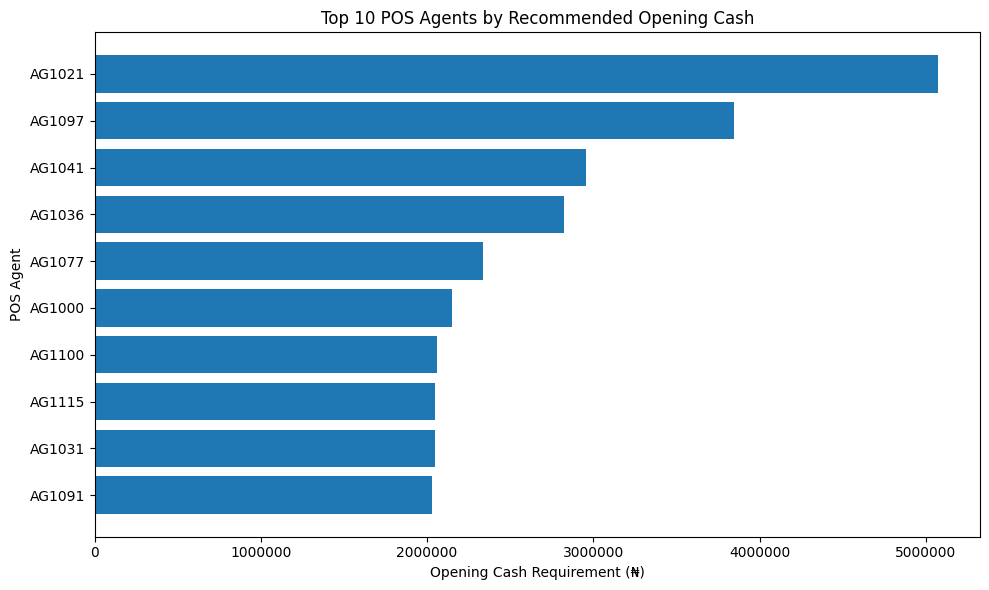

In [23]:
def plot_top_agents(agent_float, agent_ids):

    top = np.argsort(agent_float)[-10:]

    plt.figure(figsize=(10, 6))

    plt.barh(
        agent_ids[top],
        agent_float[top]
    )

    plt.xlabel("Opening Cash Requirement (₦)")
    plt.ylabel("POS Agent")

    plt.title(
        "Top 10 POS Agents by Recommended Opening Cash"
    )

    plt.ticklabel_format(
        style="plain",
        axis="x"
    )

    plt.tight_layout()
    plt.show()


plot_top_agents(agent_float, data["agent_ids"])